In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.constants as const

from scipy.integrate import quad
from tqdm import tqdm
from tqdm.contrib import itertools

from joblib import delayed, Parallel

import h5py


/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs
mu = 1.4  # mean molecular weight

Ee_arr_binedges = np.logspace(np.log10(2), 4, 51) * u.GeV  # kinetic energy
Ee_arr = np.sqrt(Ee_arr_binedges[1:] * Ee_arr_binedges[:-1])  # geometric mean
dEe_arr = (Ee_arr_binedges[1:] - Ee_arr_binedges[:-1]).to(u.GeV)

In [3]:
# parameters for taking care of normalisation of p-> e spectrum
# the observed spectrum is evaluated at 10 GeV, so we normalise energy
# then transform to normalised momentum
Kep = 0.01  # Cummings et al 2016
pp0 = ((10 * u.GeV) / c / (mp * c)).to_value(u.dimensionless_unscaled)
pe0 = ((10 * u.GeV) / c/ (me * c)).to_value(u.dimensionless_unscaled)
# pp0 = np.sqrt((ep0 + 1) ** 2 - 1)
# pe0 = np.sqrt((ee0 + 1) ** 2 - 1)
print(f"ep ratio parameters: {Kep:.2f}, {pp0:.3f}, {pe0:.3f}")

ep ratio parameters: 0.01, 10.658, 19569.512


In [4]:
def mom(Ek, mass=me):
    """Calculate momentum from kinetic energy."""
    return (np.sqrt((Ek + mass * c**2) ** 2 - (mass * c**2) ** 2) / c).to(u.g * u.cm / u.s)

# below are functions to calculation synchrotron emitting electrons
def synch_kernel(x):
    """Synchrotron kernal, as in Aharonian et al. 2010."""
    exp_factor = (1 + 0.884 * x ** (2 / 3) + 0.471 * x ** (4 / 3)) / (
        1 + 1.64 * x ** (2 / 3) + 0.974 * x ** (4 / 3)
    )
    return 2.15 * x ** (1 / 3) * (1 + 3.06 * x) ** (1 / 6) * exp_factor * np.exp(-x)


def crit_freq(Blos, eele):
    """Critical frequency as a function of magnetic field / microG and electron energy / GeV"""
    # NB: here we take normalised momentum (normalised over mass)
    return 0.5 * (Blos / (1 * u.uG)) * (np.sqrt(1 + (mom(eele) / (me * c))**2) / 1e4) ** 2 * u.GHz

def synch_coeff(Blos):
    """Coefficient in front of synchrotron integral."""
    return (np.sqrt(3) * const.e.gauss.value**3 * Blos.to_value(u.G)) / (me.value * c.value**2)

Text(0.5, 1.0, 'Critical frequency of synchrotron radiation')

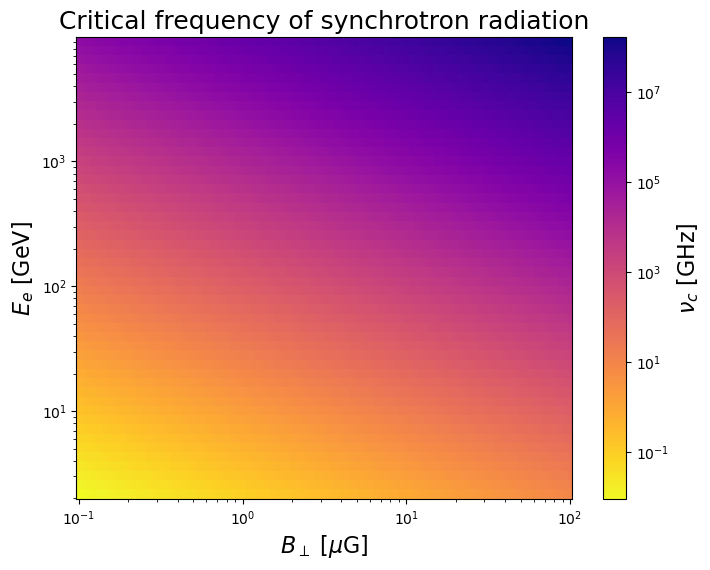

In [5]:
# plot the critical frequency as function of magnetic field and electron momentum
Blos_grid = np.logspace(-1, 2, 100) * u.uG

EELE, BLOS = np.meshgrid(Ee_arr, Blos_grid)
crit_freq_grid = crit_freq(BLOS, EELE).value

fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    EELE.value,
    crit_freq_grid,
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(),
    cmap="plasma_r",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$\nu_c$ [GHz]", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$E_e$ [GeV]", fontsize=16)

ax.set_title("Critical frequency of synchrotron radiation", fontsize=18)

Text(0.5, 1.0, 'Synchrotron Kernel')

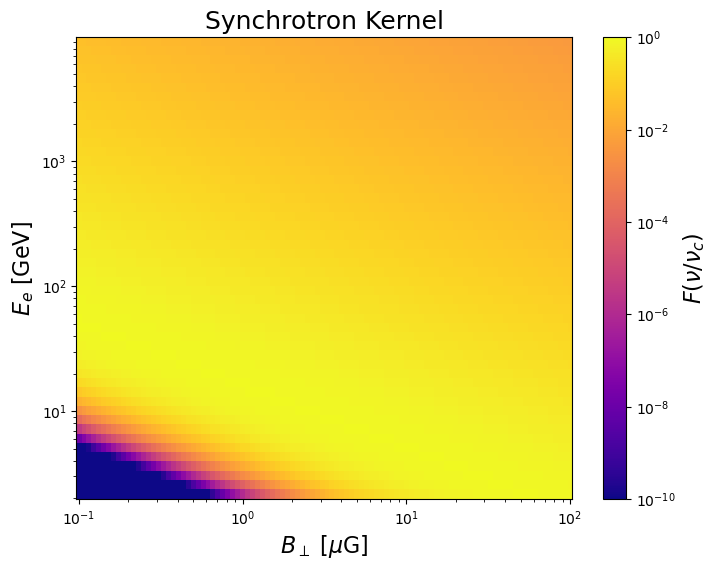

In [6]:
# synchtron kernel
# plot the critical frequency as function of magnetic field and electron momentum
Blos_grid = np.logspace(-1, 2, 100) * u.uG

EELE, BLOS = np.meshgrid(Ee_arr, Blos_grid)
crit_freq_grid = crit_freq(BLOS, EELE)

synch_freq = 1.4 * u.GHz
synch_kern = synch_kernel((synch_freq / crit_freq_grid).value)

fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    EELE.value,
    synch_kern,
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmin=1e-10, vmax=1, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$F(\nu / \nu_c)$", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$E_e$ [GeV]", fontsize=16)

ax.set_title("Synchrotron Kernel", fontsize=18)

In [7]:
alpha_e = 2.7

Text(0.5, 1.0, 'Electron spectrum weighted by Synchrotron Kernel, $\\alpha_e = 2.7$')

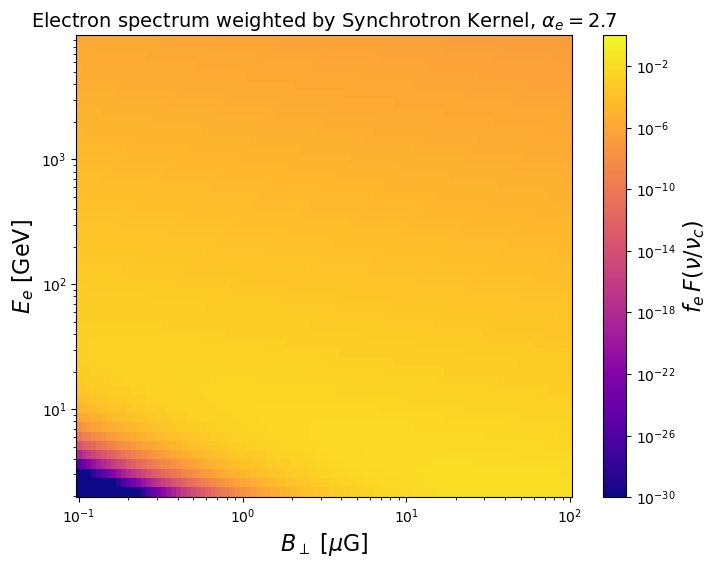

In [8]:
# synchtron kernel
# plot the critical frequency as function of magnetic field and electron momentum
Blos_grid = np.logspace(-1, 2, 100) * u.uG

EELE, BLOS = np.meshgrid(Ee_arr, Blos_grid)
crit_freq_grid = crit_freq(BLOS, EELE)

synch_freq = 1.4 * u.GHz
F_E = EELE**(-alpha_e) * (2 * mom(EELE) * c**2) / (EELE + me * c**2) * 4 * np.pi * mom(EELE)**2
F_E /= np.trapz(F_E, EELE, axis=1)[:, None]
synch_kern = F_E * synch_kernel((synch_freq / crit_freq_grid).value)

fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    EELE.value,
    synch_kern.value,
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmin=1e-30, vmax=1, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(rf"$f_e \, F(\nu / \nu_c)$", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$E_e$ [GeV]", fontsize=16)

ax.set_title(rf"Electron spectrum weighted by Synchrotron Kernel, $\alpha_e = {alpha_e}$", fontsize=14)

# ax.set_title("Fraction of CR Electrons contributing to Synchrotron Emission", fontsize=14)

Text(0.5, 1.0, 'Fraction of CR Electrons contributing to Synchrotron Emission')

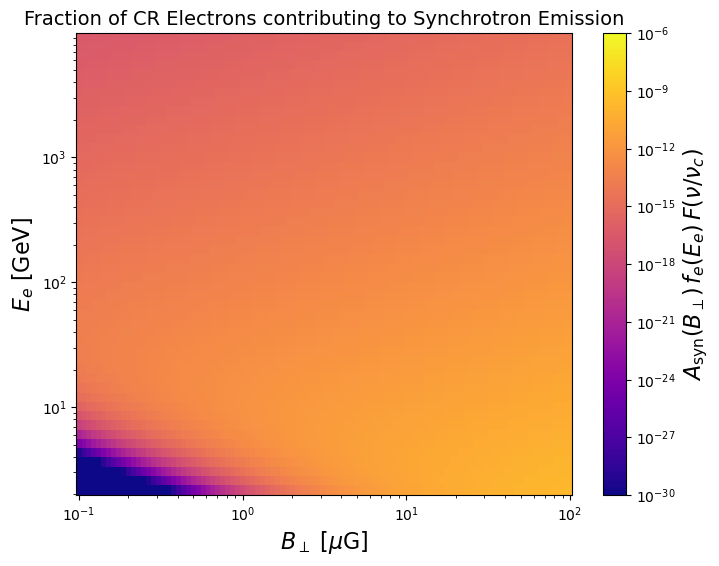

In [9]:
# synchtron kernel
# plot the critical frequency as function of magnetic field and electron momentum
Blos_grid = np.logspace(-1, 2, 100) * u.uG

EELE, BLOS = np.meshgrid(Ee_arr, Blos_grid)
crit_freq_grid = crit_freq(BLOS, EELE)

synch_freq = 1.4 * u.GHz
F_E = EELE**(-alpha_e) * (2 * mom(EELE) * c**2) / (EELE + me * c**2) * 4 * np.pi * mom(EELE)**2
F_E /= np.trapz(F_E, 4 * np.pi * mom(EELE)**2 * EELE, axis=1)[:, None]
synch_kern = synch_coeff(BLOS) * F_E * synch_kernel((synch_freq / crit_freq_grid).value) 

fig, ax = plt.subplots(figsize=(8, 6))

ax.pcolormesh(
    BLOS.value,
    EELE.value,
    synch_kern.value,
    shading="auto",
    norm=plt.matplotlib.colors.LogNorm(vmax=1e-6, vmin=1e-30, clip=True),
    cmap="plasma",
)
cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label(r"$A_\mathrm{syn}(B_\perp) \, f_e(E_e) \, F(\nu / \nu_c)$", fontsize=16)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$E_e$ [GeV]", fontsize=16)

ax.set_title("Fraction of CR Electrons contributing to Synchrotron Emission", fontsize=14)

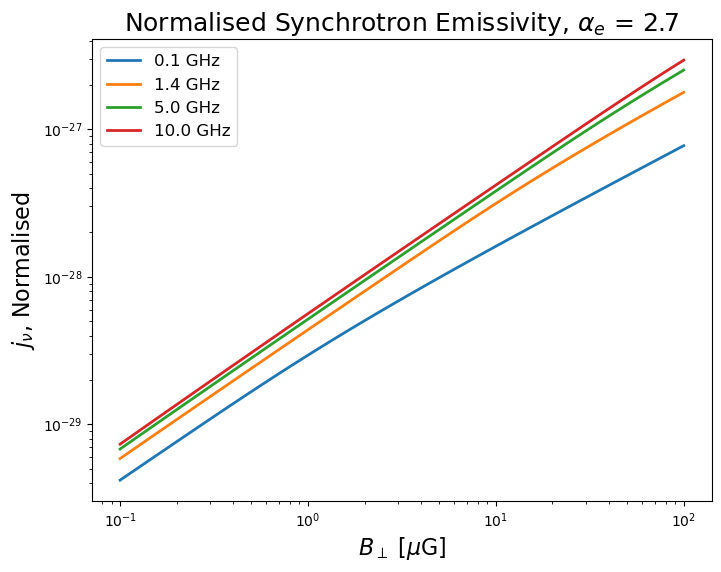

In [10]:
# synchtron kernel
# plot the critical frequency as function of magnetic field and electron momentum
Blos_grid = np.logspace(-1, 2, 100) * u.uG

EELE, BLOS = np.meshgrid(Ee_arr, Blos_grid)
crit_freq_grid = crit_freq(BLOS, EELE)
fig, ax = plt.subplots(figsize=(8, 6))

for isyn, synch_freq in enumerate([0.1, 1.4, 5, 10] * u.GHz):
    f_e = EELE**(-alpha_e) * 4 * np.pi * mom(EELE)**2 * (2 * mom(EELE) * c**2) / (EELE + me * c**2)
    f_e /= np.trapz(f_e, EELE, axis=1)[:, None]
    synch_kern = synch_coeff(BLOS) * f_e * synch_kernel((synch_freq / crit_freq_grid).value)
    synch_emiss = np.trapz(synch_kern, EELE.value, axis=1)

    ax.plot(
        Blos_grid,
        synch_emiss,
        color=f"C{isyn}",
        label=f"{synch_freq.to_value(u.GHz):.1f} GHz",
        lw=2.0
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$j_\nu$, Normalised", fontsize=16)

ax.set_title(fr"Normalised Synchrotron Emissivity, $\alpha_e$ = {alpha_e}", fontsize=18)
ax.legend(fontsize=12)

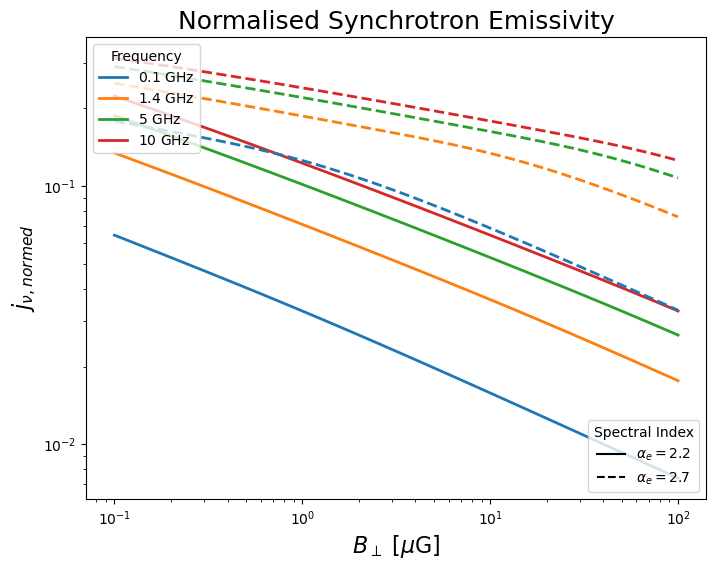

In [41]:
# synchtron kernel
# plot the critical frequency as function of magnetic field and electron momentum
Blos_grid = np.logspace(-1, 2, 100) * u.uG

EELE, BLOS = np.meshgrid(Ee_arr, Blos_grid)
crit_freq_grid = crit_freq(BLOS, EELE)
fig, ax = plt.subplots(figsize=(8, 6))

lss = ["-", "--", "-.", ":"]
for iae, ae in enumerate([2.2, 2.7]):
    for isyn, synch_freq in enumerate([0.1, 1.4, 5, 10] * u.GHz):
        f_e = EELE**(-ae) * 4 * np.pi * mom(EELE)**2 * (2 * mom(EELE) * c**2) / (EELE)
        f_e /= np.trapz(f_e, EELE, axis=1)[:, None]
        synch_kern = f_e * synch_kernel((synch_freq / crit_freq_grid).value)
        synch_emiss = np.trapz(synch_kern, EELE.value, axis=1)

        ax.plot(
            Blos_grid,
            synch_emiss,
            color=f"C{isyn}",
            label=f"{synch_freq.to_value(u.GHz):.1f} GHz",
            ls=lss[iae],
            lw=2.0
        )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$B_{\perp}$ [$\mu$G]", fontsize=16)
ax.set_ylabel(r"$j_{\nu, normed}$", fontsize=16)

ax.set_title("Normalised Synchrotron Emissivity", fontsize=18)
leg1 = ax.legend(
    handles = [plt.Line2D([0], [0], color=f"C{i}", lw=2) for i in range(4)],
    labels=[r"$0.1$ GHz", r"$1.4$ GHz", r"$5$ GHz", r"$10$ GHz"],
    loc="upper left",
    title="Frequency",
)
fig.add_artist(leg1)
ax.legend(handles=
          [plt.Line2D([0], [0], color="k", ls=lss[i]) for i in range(len(lss))],
    labels=[r"$\alpha_e = 2.2$", r"$\alpha_e = 2.7$"],
    loc="lower right",
    title="Spectral Index",
)

## Now apply this to a single simulation

In [12]:
import json
import flash_amr_tools

flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

sim_name = "ISM-v30"

In [13]:
def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

Define the primary electron as some fraction of the total CR proton population.

For secondary electrons, we assume they all come from charged hadronic emission (2/3) and that electrons get 1/4 of the energy of pions -> 1/6 factor of the hadronic emission

In [14]:
time = 180 * u.kyr

In [54]:
# set the primary electron fraction to be ~ 0.01
# cre_prim_factor = 0.02
eV_to_erg = 6.242e11
ionisation_rate = 3e-17 * eV_to_erg * u.s**-1  # as in Brugaletta+2025
cre_prim_factor = ionisation_rate * time.to(u.s)

sigma_pp = 44 * u.mbarn  # total pion cross section
Kp = 0.5  # inelasticity
mol_weight = 1.4  # mean molecular weight
Bhadr_coeff = (const.c.cgs * sigma_pp * Kp / (const.m_p.cgs * mol_weight)).cgs  # hadronic loss coefficient

cre_second_factor = 1/6 * Bhadr_coeff * (time).to(u.s)

print(cre_prim_factor, cre_second_factor)

106370571.168 2.666507348845522e+20 cm3 / g


In [55]:
# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

# get list of all files
sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])
sim_file = find_hdf5_file_from_time(time, sim_dir)

print(sim_file)

/home/kwatanabe/Projects/cr-bowshocks/outputs_new/ISM_v30_CR/starISM_hdf5_plt_cnt_0020


In [56]:
pf = h5py.File(os.path.join(sim_dir, sim_file), "r")

# load the data
blist, brefs, bns = flash_amr_tools.get_true_blocks(
    os.path.join(sim_dir, sim_file)
)

minimum position of the region of interest:  [-7.71419395e+19 -7.71419395e+19 -7.71419395e+19]
maximum position of the region of interest:  [2.31425819e+20 7.71419395e+19 7.71419395e+19]
Finding all leaf blocks in given region
82560 82560
Biggest block has refinement level: 4
Highest refinement level in simulation: 7
Highest refinement level in selected box: 7
Extending region to fit amr structure at level 4.


Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 94208
Region extended to:	lower		upper
	x	-7.71419469e+19		+2.31425806e+20
	y	-7.71419469e+19		+7.71419469e+19
	z	-7.71419469e+19		+7.71419469e+19

Region center at:	+7.71419293e+19	+0.00000000e+00	+0.00000000e+00
Given center:		+7.71419398e+19	+0.00000000e+00	+0.00000000e+00


In [57]:
encr_data = pf["encr"][()][blist] * pf["dens"][()][blist] * u.erg / u.cm**3
dens_data = pf["dens"][()][blist] * u.g / u.cm**3

j_ele_prim_data = cre_prim_factor * encr_data
j_ele_second_data = cre_second_factor * dens_data * encr_data
print(np.min(j_ele_prim_data), np.max(j_ele_prim_data))
print(np.min(j_ele_second_data), np.max(j_ele_second_data))

j_electron_data = cre_prim_factor * encr_data + cre_second_factor * dens_data * encr_data
print(np.min(j_electron_data), np.max(j_electron_data))
print(np.min(encr_data), np.max(encr_data))

1.0536473382671829e-07 erg / cm3 0.0008605898474343121 erg / cm3
8.563014917553518e-24 erg / cm3 1.8286543476296255e-15 erg / cm3
1.0536473382671829e-07 erg / cm3 0.0008605898474343121 erg / cm3
9.90544045441702e-16 erg / cm3 8.090488348710956e-12 erg / cm3


In [58]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

In [59]:
ref_lvl = pf["refine level"][()][blist]
bbox = pf["bounding box"][()][blist]
bsize = pf["block size"][()][blist]
low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]
extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

Text(0, 0.5, '$j_{e, prim}$ / erg cm$^{-3}$')

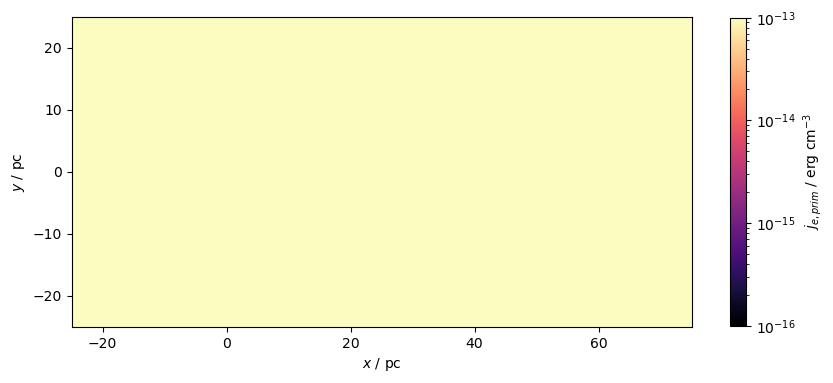

In [60]:
j_ele_sl = flash_amr_tools.get_slice(cre_prim_factor * encr_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots(figsize=(10,8))
norm = mcolors.LogNorm(vmin=1e-16, vmax=1e-13, clip=True)

im = ax.imshow(j_ele_sl.T, norm=norm, cmap=cm.magma, alpha=1.0, interpolation="none", extent=extent)
# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.ax.set_ylabel(r"$j_{e, prim}$ / erg cm$^{-3}$")

Text(0, 0.5, '$j_{e, second}$ / erg cm$^{-3}$')

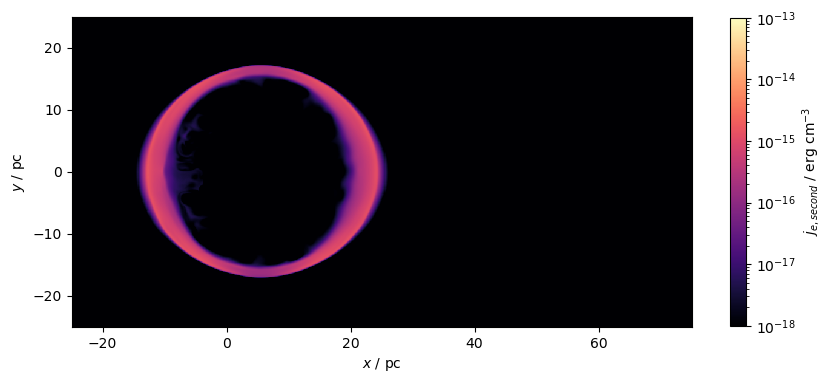

In [61]:
j_ele_sl = flash_amr_tools.get_slice(cre_second_factor.value * dens_data * encr_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots(figsize=(10,8))
norm = mcolors.LogNorm(vmin=1e-18, vmax=1e-13, clip=True)

im = ax.imshow(j_ele_sl.T, norm=norm, cmap=cm.magma, alpha=1.0, interpolation="none", extent=extent)
# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.ax.set_ylabel(r"$j_{e, second}$ / erg cm$^{-3}$")

Text(0, 0.5, '$j_e$ / erg cm$^{-3}$')

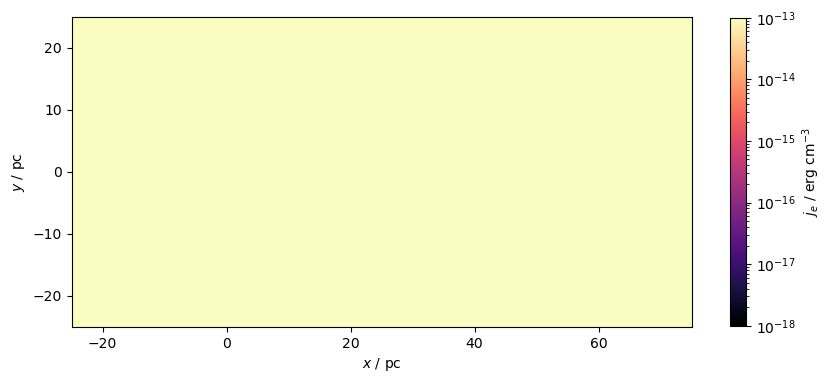

In [62]:
j_ele_sl = flash_amr_tools.get_slice(j_electron_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots(figsize=(10,8))
norm = mcolors.LogNorm(vmin=1e-18, vmax=1e-13, clip=True)

im = ax.imshow(j_ele_sl.T, norm=norm, cmap=cm.magma, alpha=1.0, interpolation="none", extent=extent)
# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.ax.set_ylabel(r"$j_e$ / erg cm$^{-3}$")

In [63]:
f_e = Ee_arr**(-alpha_e) * 4 * np.pi * mom(Ee_arr)**2 * (2 * mom(Ee_arr) * c**2) / (Ee_arr + me * c**2)
f_e /= np.trapz(f_e, Ee_arr, axis=0)

def synch_emissivity(Blos, synch_freq=10*u.GHz, alpha_e=2.7):
    """Calculate synchrotron emissivity for a given magnetic field."""
    synch_emiss = np.zeros_like(Blos.value)

    for ie, eele in tqdm(enumerate(Ee_arr)):
        crit_freq_grid = crit_freq(Blos.to(u.uG), eele)
        crit_freq_grid = np.clip(crit_freq_grid, 1e-5 * u.GHz, None)

        synch_kern = synch_coeff(Blos) * f_e[ie].value * synch_kernel((synch_freq / crit_freq_grid).value)
        synch_emiss += synch_kern * dEe_arr[ie].to_value(u.GeV)
    
    return synch_emiss

In [64]:
Blos_data = (2/3) * np.sqrt(pf["magx"][()][blist] ** 2 + pf["magy"][()][blist] ** 2 + pf["magz"][()][blist]**2) * u.G
j_synch_normed = synch_emissivity(Blos_data.to(u.uG), synch_freq=10*u.GHz, alpha_e=2.2)

50it [02:10,  2.61s/it]


Text(0, 0.5, '$j_\\mathrm{syn, normed}$')

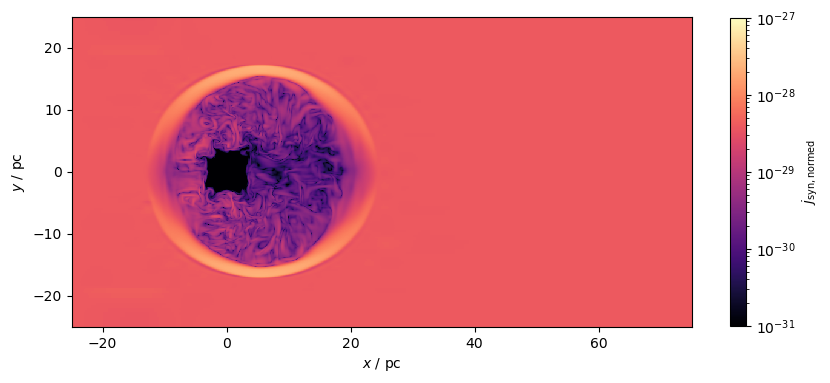

In [65]:
j_synch_normed_sl = flash_amr_tools.get_slice(j_synch_normed, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots(figsize=(10,8))
norm = mcolors.LogNorm(vmin=1e-31, vmax=1e-27, clip=True)

im = ax.imshow(j_synch_normed_sl.T, norm=norm, cmap=cm.magma, alpha=1.0, interpolation="none", extent=extent)
# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.ax.set_ylabel(r"$j_\mathrm{syn, normed}$")

In [66]:
j_synch_data = j_synch_normed * j_electron_data

print(np.min(j_synch_data), np.max(j_synch_data))

0.0 erg / cm3 8.419568213082472e-32 erg / cm3


Text(0, 0.5, '$j_\\mathrm{syn}$ / erg cm$^{-3}$ s$^{-1}$ Hz$^{-1}$')

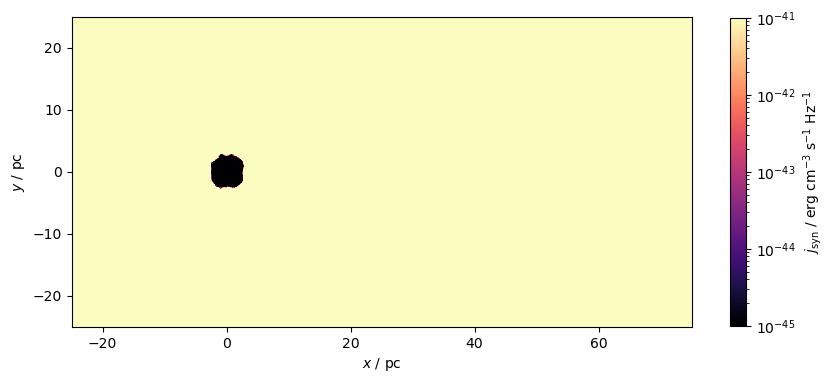

In [67]:
j_synch_sl = flash_amr_tools.get_slice(j_synch_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots(figsize=(10,8))
norm = mcolors.LogNorm(vmin=1e-45, vmax=1e-41, clip=True)

im = ax.imshow(j_synch_sl.T, norm=norm, cmap=cm.magma, alpha=1.0, interpolation="none", extent=extent)
# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.ax.set_ylabel(r"$j_\mathrm{syn}$ / erg cm$^{-3}$ s$^{-1}$ Hz$^{-1}$")

Text(0, 0.5, '$j_\\mathrm{syn, 10GHz}$ / erg cm$^{-3}$ s$^{-1}$')

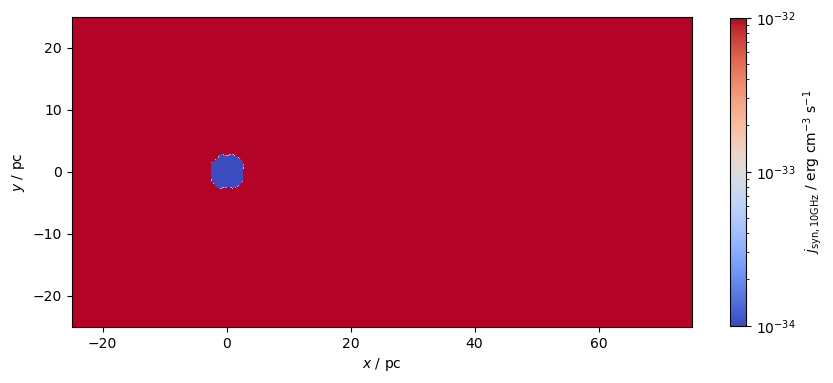

In [68]:
j_synch_sl = flash_amr_tools.get_slice(j_synch_normed * j_electron_data, pos=0.0, axis=2, ref_lvl=ref_lvl, bbox=bbox, bsize=bsize, brefs=brefs, bns=bns)

# plot
fig, ax = plt.subplots(figsize=(10,8))
norm = mcolors.LogNorm(vmin=1e-34, vmax=1e-32, clip=True)

im = ax.imshow(j_synch_sl.T * 1.4e9, norm=norm, cmap=cm.coolwarm, alpha=1.0, interpolation="none", extent=extent)
# labels
ax.set_xlabel("$x$ / pc")
ax.set_ylabel("$y$ / pc")

cb = fig.colorbar(im, ax=ax, shrink=0.5)
cb.ax.set_ylabel(r"$j_\mathrm{syn, 10GHz}$ / erg cm$^{-3}$ s$^{-1}$")

In [69]:
np.where(np.isnan(j_synch_data))

(array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64))

In [70]:
cell_size_data = (
    np.tile(bsize[:, 0] / 8.0, reps=(8, 8, 8)).reshape((bsize.shape[0], 8, 8, 8))
    * u.cm
).to_value(u.pc)

Lsynch = ((j_synch_data).to(u.erg * u.pc**-3) * cell_size_data**3).value

print(np.sum((j_synch_data).to(u.erg * u.pc**-3) * cell_size_data**3).value * (10e9))

5.517307241262573e+38


In [71]:
# synch_freqs = np.array([0.5, 1.4, 5, 10]) * u.GHz # in GHz
# synch_lum_freq = np.array([4.42e28, 1.43e29,6.025e29, 1.3e30])

# a, b = np.polyfit(np.log10(synch_freqs.to_value(u.GHz)), np.log10(synch_lum_freq), 1)
# print(a, b)

In [72]:
# synch_freqs = np.array([0.5, 1.4, 5, 10]) * u.GHz # in GHz
# synch_lum_freq = np.array([4.42e28, 1.42e29,6.025e29, 1.31e30])

# fig, ax = plt.subplots()
# ax.plot(synch_freqs.to(u.Hz), synch_lum_freq, label="ISM-v30-LDiff")

# ax.plot(
#         synch_freqs.to_value(u.Hz),
#         1e26 * (synch_freqs.to_value(u.Hz))**(-(2.2 - 3) / 2),
#         color="k",
#         label=r"$\propto \nu^{-(s-3)/2}, \: s=2.2$",
#         ls="--",
#         lw=2.0,
#     )
# # plot data also
# data_colors = ["gray", "gray"]
# data_symbols = ["o", "d"]
# data_labels = ["BD+43° 3654 (Moutzouri+2022)", "BD+60° 2522 (Moutzouri+2022)"]

# data_handles = []
# with h5py.File(f"{data_dir}/M22_data.h5", "r") as pf:
#     for l, (bs_name, vd) in enumerate(list(pf.items())):
#         synch_freq_data = vd["freq"][()] * u.GHz
#         freq_err = 0.5 * u.GHz  # width of each sub-band
#         d, d_err = vd["D"][()] * u.kpc
#         flux = vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
#         print(flux)
#         # pure flux is 5% calibration uncertainty, but data is nu * flux so we have to include
#         # frequency error for flux error calculation
#         flux_err = flux * np.sqrt(0.05**2 + (freq_err / synch_freq_data) ** 2)

#         # calcualte luminosity
#         synch_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
#         synch_lum_data_err = (
#             4 * np.pi * np.sqrt((2 * d * flux * d_err) ** 2 + (d**2 * flux_err) ** 2)
#         ).to(u.erg * u.s**-1)

#         print(synch_lum_data)

#         errorbar = ax.errorbar(
#             synch_freq_data.to(u.Hz),
#             synch_lum_data,
#             xerr=freq_err.to(u.Hz),
#             yerr=synch_lum_data_err,
#             label=data_labels[l],
#             marker=data_symbols[l],
#             alpha=1.0,
#             ls="",
#             ms=6.0,
#             color=data_colors[l],
#             zorder=100
#         )

#         data_handles.append(errorbar)

# ax.set_ylim(ymin=1e28, ymax=1e33)
# ax.set_xlim(xmin=8e8, xmax=1e10)

# freq_ls2355 = 944 * u.MHz
# freq_ls2355_err = 288 * u.MHz
# flux_density_ls2355 = 79.4 * u.mJy
# flux_density_ls2355_err = 0.8 * u.mJy
# d_ls2355 = 2.2 * u.kpc
# d_ls2355_err = 0.1 * u.kpc
# synch_lum_ls2355 = (4 * np.pi * d_ls2355**2 * flux_density_ls2355 * freq_ls2355).to(u.erg / u.s)
# synch_lum_ls2355_err = (
#     4 * np.pi * np.sqrt(
#         (2 * d_ls2355 * freq_ls2355 * flux_density_ls2355 * d_ls2355_err) ** 2
#         + (d_ls2355**2 * freq_ls2355 * flux_density_ls2355_err) ** 2
#         + (d_ls2355**2 * flux_density_ls2355 * freq_ls2355_err) ** 2
#     )
# ).to(u.erg / u.s)

# errorbar = ax.errorbar(
#     freq_ls2355.to_value(u.Hz),
#     synch_lum_ls2355,
#     xerr=freq_ls2355_err.to_value(u.Hz),
#     yerr=synch_lum_ls2355_err,
#     label="LS 2355 (van den Eijnden+2024)",
#     marker="s",
#     alpha=1.0,
#     ls="",
#     ms=6.0,
#     color="gray",
#     zorder=100
# )
# data_handles.append(errorbar)

# ax.set_xscale("log")
# ax.set_yscale("log")

# ax.set_xlabel(r"$\nu$ [Hz]")
# ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")

# ax.legend(framealpha=0, frameon=False, fontsize=12)